## Import Libraries

In [9]:
# For data manipulation
import pandas as pd
import requests
from io import StringIO

# For fetch financial data
import yfinance as yf

# For visualization
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

## Data for Multiple Assets

In [2]:
# Define the ticker list
tickers_list = ["AAPL", "AMZN", "MSFT"]

# Download the data for the above tickers and extract the Close column
price_data = yf.download(tickers=tickers_list, start="2019-01-01")["Close"]

# Set the index to a datetime object
price_data.index = pd.to_datetime(price_data.index)

# Display the first 5 rows
price_data.head()

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,AMZN,MSFT
Date,,,
2019-01-02,37.469200,76.956497,94.193138
2019-01-03,33.736988,75.014000,90.727966
2019-01-04,35.177200,78.769501,94.947639
2019-01-07,35.098904,81.475502,95.068748
2019-01-08,35.768002,82.829002,95.758034


## Plot the Series

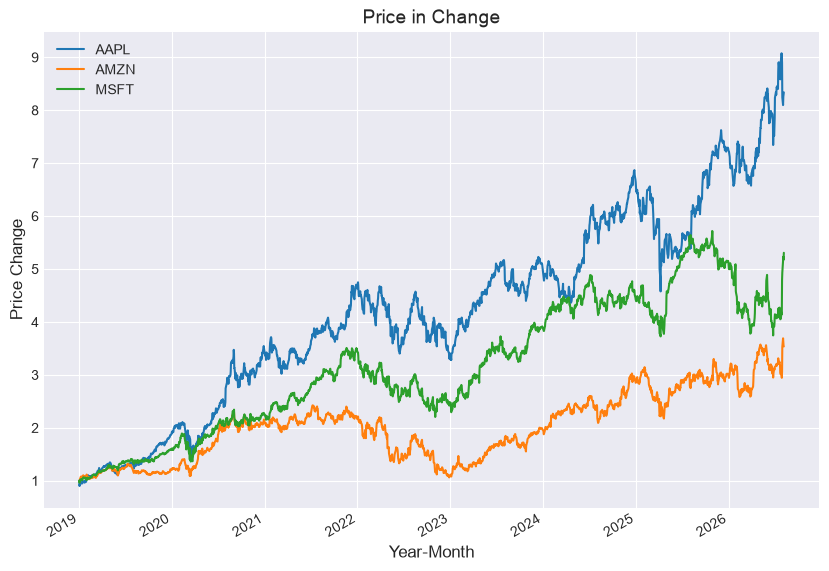

In [3]:
# Plot the absolute price series
plt.figure(figsize=(10, 7))
(price_data["AAPL"]/price_data["AAPL"].iloc[0]).plot()
(price_data["AMZN"]/price_data["AMZN"].iloc[0]).plot()
(price_data["MSFT"]/price_data["MSFT"].iloc[0]).plot()

# Set the title and axes label
plt.title("Price in Change", fontsize=14)
plt.xlabel("Year-Month", fontsize=12)
plt.ylabel("Price Change", fontsize=12)
plt.legend()

# Show the plot
plt.show()

## Data for Assets Constituting S&P 500

In [10]:
# url of the source
# URL of the source

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

headers = {

    "User-Agent": (

        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "

        "AppleWebKit/537.36 (KHTML, like Gecko) "

        "Chrome/120.0.0.0 Safari/537.36"

    )

}
response = requests.get(url, headers=headers, timeout=30)

response.raise_for_status()

# Parse HTML tables

tables = pd.read_html(StringIO(response.text))

# Find the table containing the S&P 500 constituents

tickers = next(

    df for df in tables

    if {"Symbol", "Security"}.issubset(df.columns)

)

tickers.head()

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [15]:
 # Convert (the ticker) column to list
ticker_symbol = (tickers["Symbol"].str.replace(".", "-", regex=False).tolist())

# Get the data for this tickers from yfinance
data = yf.download(ticker_symbol,start="2021-01-01",auto_adjust=True)["Close"]
data.head()

[*********************100%***********************]  503 of 503 completed


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.179115,125.740837,84.736267,139.149994,97.868500,33.186359,233.890686,485.339996,133.026703,42.777458,...,26.364799,103.407829,55.198765,33.466633,93.369881,221.160004,95.495239,141.976410,378.130005,153.987732
2021-01-05,115.112617,127.295471,85.612495,148.300003,99.079399,33.319485,235.222229,485.690002,135.404434,43.609509,...,26.613894,106.590347,54.660732,35.079483,93.257492,229.750000,95.504265,144.432907,380.570007,155.060806
2021-01-06,118.269295,123.010521,84.872940,142.770004,98.873085,34.783871,237.794022,466.309998,136.014832,45.376530,...,26.750507,107.228767,55.871311,35.974621,97.191216,226.889999,96.027664,148.548691,394.820007,157.338745
2021-01-07,121.416359,127.208015,85.781296,151.270004,99.832855,34.460564,240.037582,477.739990,141.763367,44.973377,...,27.007643,106.164719,54.778423,36.256866,101.602615,239.479996,95.296684,147.668045,409.100006,157.197556
2021-01-08,122.282516,128.306030,86.231468,149.770004,100.110916,34.650742,240.913116,485.100006,142.792816,45.093456,...,26.822826,105.468246,55.282829,36.660076,100.572357,241.449997,96.695457,147.343597,405.470001,158.242401
